# Raspberry Pi Camera and YOLO Object Detection

This notebook shows how a Raspberry Pi can use a camera and a YOLO AI model to recognize objects.

- **The camera** provides a live image.
- **YOLO** looks at the image and predicts what objects appear in it.
- **OpenCV** draws boxes and labels around detected objects.
- **UGOT** moves the robot and operates the arm after the object is found.

Run the notebook cells from top to bottom. Each code cell is explained by comments beside the commands.

In [ ]:
# Note: only run this cell if you have access to the UGOT robot. This code is to connect to the robot.
# ugot contains the instructions used to communicate with the robot.
from ugot import ugot
got = ugot.UGOT()  # This object represents the UGOT robot.
# Replace this IP address if the robot has a different address on the network.
got.initialize('192.168.1.61')
got.open_camera()  # Ask the robot to start sending camera images.

In [ ]:
# time gives us access to waiting and timing tools.
import time

# Camera 1 is used here. A camera number of 0 or 1 may be needed,
# depending on whether this is a Raspberry Pi or another computer.
PI_CAMERA = 1

# ultralytics provides YOLO, the AI model used for object recognition.
import ultralytics
from ultralytics import YOLO

# cv2 (OpenCV) reads and edits images. numpy handles image data efficiently.
import cv2
import numpy as np

# These notebook tools display live images and replace old frames.
from IPython.display import Image, display, clear_output

ultralytics.checks()  # Confirm that YOLO and its supporting software are available.
model = YOLO("yolo26n.pt")  # Load the pre-trained YOLO model from this file.
print("Model is ready.")

Ultralytics 8.3.234  Python-3.13.12 torch-2.10.0+cpu CPU (Intel Core i7-1065G7 1.30GHz)
Setup complete  (8 CPUs, 15.8 GB RAM, 289.1/342.4 GB disk)
Model is ready.


Next, we will test the YOLO model object detection. The full list of 80 objects that this model is trained on is [here](https://gist.github.com/rcland12/dc48e1963268ff98c8b2c4543e7a9be8).

The camera is on


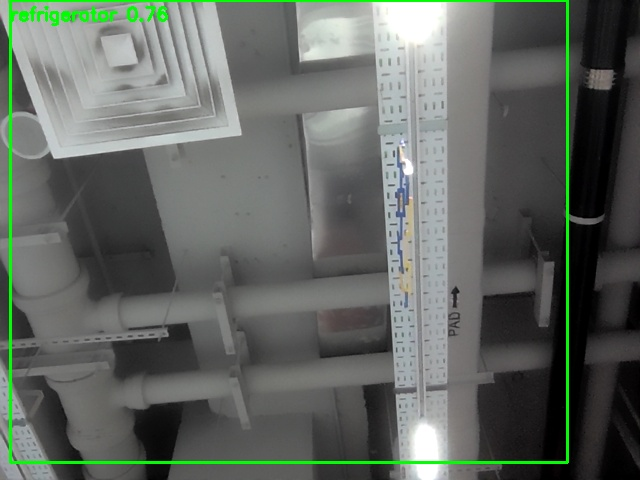

Test finished.


In [7]:
# Live camera test: Raspberry Pi camera only, with no robot movement.
# VideoCapture opens the selected camera and creates a continuous video stream.
camera = cv2.VideoCapture(PI_CAMERA)
if isinstance(PI_CAMERA, int):
    camera.set(cv2.CAP_PROP_FOURCC, cv2.VideoWriter_fourcc(*'MJPG'))

if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on")
    handle = None
    try:
        while True:
            frame_ok, frame = camera.read()
            if not frame_ok:
                continue

            results = model(frame, verbose=False)
            for box in results[0].boxes:
                name = model.names[int(box.cls[0])]
                conf = float(box.conf[0])
                x1, y1, x2, y2 = map(int, box.xyxy[0])
                cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(frame, f"{name} {conf:.2f}", (x1, max(y1 - 10, 20)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

            jpeg_ok, jpeg = cv2.imencode(".jpg", frame)
            if jpeg_ok:
                if handle is None:
                    handle = display(Image(data=jpeg.tobytes()), display_id=True)
                else:
                    handle.update(Image(data=jpeg.tobytes()))
    except KeyboardInterrupt:
        pass
    finally:
        camera.release()
        print("Test finished.")

The next cell defines functions to control the robot, so that you can complete the challenges.

In [ ]:
# This function searches live camera pictures for one named object.
# It stops three seconds after the first clear match is found.
def object_recognition_laptop(target):
    # Open the camera and prepare it as a video stream.
    camera = cv2.VideoCapture(PI_CAMERA)
    if isinstance(PI_CAMERA, int):
        camera.set(cv2.CAP_PROP_FOURCC, cv2.VideoWriter_fourcc(*'MJPG'))
    if not camera.isOpened():
        print("The camera is not opened. Check PI_CAMERA and the camera connection.")
        return

    print("The camera is on")
    time.sleep(1)  # Give the camera time to warm up and become stable.
    handle = None  # Stores the notebook display for updating later frames.
    object_found = None  # None means the target has not been found yet.
    try:
        # Keep looking until 3 seconds have passed after finding the target.
        while object_found is None or time.time() - object_found < 3:
            frame_ok, frame = camera.read()
            if not frame_ok:
                continue
            # YOLO predicts what objects are visible in this frame.
            results = model(frame, verbose=False)
            for box in results[0].boxes:
                name = model.names[int(box.cls[0])]
                if name == target:
                    # Record when the target was first found.
                    if object_found is None:
                        object_found = time.time()
                    conf = float(box.conf[0])
                    x1, y1, x2, y2 = map(int, box.xyxy[0])
                    cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
                    cv2.putText(frame, f"{name} {conf:.2f}", (x1, y1 - 10),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
            # handle block
            jpeg_ok, jpeg = cv2.imencode(".jpg", frame)
            if jpeg_ok:
                if handle is None:  # create the display area for the first time
                    handle = display(Image(data=jpeg.tobytes()), display_id=True)
                else:  # update the same display area
                    handle.update(Image(data=jpeg.tobytes()))
    finally:
        camera.release()
# Turn towards the target and move closer until it fills enough of the image.
def curve_approach_stop(target, threshold):
    got.open_camera()
    print("The camera is on.")
    time.sleep(1)

    while True:
        # Read the next image directly from the robot camera.
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            continue
        
        # Convert the robot's image bytes into an OpenCV image.
        frame = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)
        # YOLO looks for the selected object in this robot image.
        results = model(frame,verbose = False)
        cx = None  # The target's horizontal centre is unknown until it is found.
        width = None  # The target's width is unknown until it is found.
        for box in results[0].boxes:
            name = model.names[int(box.cls[0])]
            conf = float(box.conf[0])
            if name == target:
                x1,y1,x2,y2 = map(int,box.xyxy[0])
                cx =(x1+x2)//2
                cy =(y1+y2)//2
                width = x2-x1
                cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
                cv2.circle(frame,(cx,cy),2,(0,255,255),2)
                cv2.putText(frame,f"{name} {conf:.2f} cx:{cx}width:{width}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        display(Image(picture_jpg.tobytes()))
        clear_output(True)
        
        # If the target is not visible, turn right slowly and keep searching.
        if cx is None:
            got.mecanum_move_xyz(0,10,0)
        # If the target is close and roughly centred, stop the robot.
        elif width>threshold and 290<cx<360:
            got.mecanum_stop()
            break
        else:
            # Move forward while turning left or right to centre the target.
            got.mecanum_move_xyz(0,10,(320-cx)//4)
# Keep turning until the selected object is found, then stop.
def patrol_recognize (target):
    while True:
        # Read the next image from the robot camera.
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            continue
        
        frame = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)
        # YOLO block
        results = model(frame,verbose = False)
        cx = None  # No matching object has been found in this frame yet.
        for box in results[0].boxes:
            name = model.names[int(box.cls[0])]
            conf = float(box.conf[0])
            if name == target:
                x1,y1,x2,y2 = map(int,box.xyxy[0])
                cx =(x1+x2)//2
                cy =(y1+y2)//2
                cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
                cv2.circle(frame,(cx,cy),2,(0,255,255),2)
                cv2.putText(frame,f"{name} {conf:.2f} cx:{cx}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)

        ok,picture_jpg = cv2.imencode(".jpg",frame)
        display(Image(picture_jpg.tobytes()))
        clear_output(True)
        
        # cx is set when an object was found, so the robot can stop.
        if cx:
            time.sleep(1)
            got.mecanum_stop()
            break
        got.mecanum_move_xyz(0,10,30)

# Run YOLO on the laptop camera for ten seconds instead of the robot camera.
def laptop_YOLO():
    import time
    # open the laptop camera
    camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)  #Macbook
    #Windows: camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)
    if not camera.isOpened():
        print("The camera is not opened.")
    else:
        print("The camera is on")
        time.sleep(1)
        handle = None
        start_time = time.time()
        while time.time()-start_time<10:
            frame_ok,frame = camera.read()
            if not frame_ok:
                continue
            # YOLO block
            results = model(frame,verbose = False)
            for box in results[0].boxes:
                name = model.names[int(box.cls[0])]
                conf = float(box.conf[0])
                x1,y1,x2,y2 = map(int,box.xyxy[0])
                cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
                cv2.putText(frame,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
            # handle block    
            if frame_ok:
                jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
                if jpeg_ok:
                    if handle is None: # create the display area for the first time
                        handle = display(Image(data=jpeg.tobytes()),display_id = True)
                    else: # update the same display area
                        handle.update(Image(data=jpeg.tobytes()))


The following cells demonstrate how to control the robot arm.

In [ ]:
got.mechanical_clamp_release()  # Open the gripper

In [ ]:
got.mechanical_clamp_close()  # Close the gripper

In [ ]:
# Move every arm joint to the starting angle (straight ahead). The last number is motion time in milliseconds.
got.mechanical_joint_control(0, 0, 0, 400)

In [ ]:
# Turn the arm 50 degrees in one direction.
got.mechanical_joint_control(50, 0, 0, 400)

In [ ]:
# Turn the arm 50 degrees in the opposite direction.
got.mechanical_joint_control(-50, 0, 0, 400)

Below, you will find sample code for completing the given challenges.

In [ ]:
# Challenge 1: find a cup, patrol towards it, and approach it until it is close.
object_recognition_laptop("cup")
patrol_recognize ("cup")
curve_approach_stop("cup", 120)

In [ ]:
# Pick up: open, lower, grasp, wait, and lift the arm.
got.mechanical_clamp_release()  # Open the gripper.
time.sleep(1)                   # Allow time for the gripper to open.
got.mechanical_joint_control(0, -30, 0, 400)  # Lower the arm.
time.sleep(1)                   # Allow time for the arm to descend.
got.mechanical_clamp_close()    # Close the gripper around the object.
time.sleep(1)                   # Allow time for the gripper to close.
got.mechanical_joint_control(45, 30, 30, 400)  # Lift the arm away from the camera.

In [ ]:
# Challenge 2: find a teddy bear, patrol towards it, and approach it until it is close.
object_recognition_laptop("teddy bear")
patrol_recognize ("teddy bear")
curve_approach_stop("teddy bear", 300)